# Module 15: Advanced Python-SQL Integration
**ALY 6420 | PostgreSQL writes, SQLAlchemy, DuckDB and analytical storytelling**

*Course Lecture Notes - Phase 4, Week 15*

## Module overview
We move from retrieving data (Module 14) to persisting validated results, managing connections and querying local analytical data. 

### Learning objectives
- Write DataFrames and programmatically generated rows to PostgreSQL safely.
- Explain transactions, SQLAlchemy Core and connection pools.
- Query DataFrames and files with DuckDB and explain when to keep computation in PostgreSQL.
- Communicate business questions, query decisions, evidence and limitations to a mixed audience.

### Study resources
Shan et al. (2025), *SQL for Data Analytics*, 4th ed., Chapter 4: SQLAlchemy and pandas (pp. 72–75), writing data (p. 75),  
The specific executemany, pooling and DuckDB examples below extend the textbook using the Canvas material and official API references. 

Install in the environment that runs Jupyter: `python -m pip install pandas sqlalchemy psycopg2-binary duckdb matplotlib jupyter`. Optional: `plotly pyarrow`. Restart the kernel after installation. Run cells in order. SQL fences are for DBeaver, not Python cells.

**Safety:** Offline mode uses an ephemeral SQLite database for portable SQLAlchemy exercises; it is not a PostgreSQL emulator. Live mode is opt-in; examples write only to session-local PostgreSQL temporary tables. 

In [1]:
#!pip install sqlalchemy
import os
from contextlib import closing
import pandas as pd
from sqlalchemy import create_engine, text, String, Integer
from sqlalchemy.engine import make_url
from sqlalchemy.pool import QueuePool
import matplotlib.pyplot as plt
LIVE = False
if LIVE:
    url = make_url(os.environ['DB_URL']).set(drivername='postgresql+psycopg2')
    url = url.update_query_dict({'sslmode': 'require'})
    engine = create_engine(url, pool_size=3, max_overflow=2,
                           pool_timeout=30, pool_pre_ping=True)
else:
    engine = create_engine('sqlite:///:memory:')
with engine.connect() as conn:
    print(conn.execute(text('SELECT 1')).scalar_one())

1


The expected connection test is 1. Set DB_URL securely outside the notebook before switching LIVE on; do not print the URL or commit credentials. Engine construction is lazy: the test forces a real connection.

## Synthetic Dataset

In [2]:
df_customers = pd.DataFrame({'customer_id':[1,2,3,4], 'city':['Seattle','Portland','Seattle','Austin'], 'state':['WA','OR','WA','TX']})
df_sales = pd.DataFrame({'customer_id':[1,2,1,3,4,2], 'sales_channel':['online','store','store','online','online','store'], 'sales_amount':[100,200,150,300,250,100]})
summary = pd.DataFrame({'product':['EV-Scooter S1','EV-Scooter S2'], 'units':[42,18]})
assert df_sales.sales_amount.sum() == 1100
summary

,product,units
0,EV-Scooter S1,42
1,EV-Scooter S2,18


Two summary rows contain 60 units. Six synthetic sales total $1,100. Customer IDs are unique in the customer fixture, so joining cannot multiply sales rows.

## Part 1 - Writing data back to PostgreSQL (15.2)
### 1.1 Choose a write method
Use `to_sql` for a DataFrame; use `executemany` for a sequence of parameter sets. For very large loads consider PostgreSQL COPY or psycopg2 fast execution helpers after measuring. Neither method is automatically an upsert.

| if_exists | Effect | Appropriate use |
|---|---|---|
| fail | Refuse an existing table | New owned staging tables |
| append | Insert more rows | Controlled incremental load |
| replace | Drop and recreate | Disposable sandbox only |

Later pandas versions also offer `delete_rows`; it is destructive and not required here. `index=False` avoids storing the pandas index as a data column. Use `dtype` for explicit types and `chunksize` for batch size; batches are not necessarily separate commits. The textbook uses replace for its own disposable table; we use fail and explicit temporary tables instead. Raw psycopg2 connections are not supported by pandas for PostgreSQL writes; SQLAlchemy Engine or Connection is appropriate (other backends such as SQLite and supported ADBC are exceptions to a universal engine requirement).

In [3]:
with engine.begin() as conn:
    conn.execute(text('CREATE TEMP TABLE m15_summary (product VARCHAR(80) PRIMARY KEY, units INTEGER NOT NULL CHECK (units >= 0))'))
    before = conn.execute(text('SELECT COUNT(*) FROM m15_summary')).scalar_one()
    summary.to_sql('m15_summary', conn, if_exists='append', index=False,
                   dtype={'product': String(80), 'units': Integer()}, chunksize=100)
    after = conn.execute(text('SELECT COUNT(*) FROM m15_summary')).scalar_one()
    saved = pd.read_sql(text('SELECT product, units FROM m15_summary ORDER BY product'), conn)
    assert after-before == len(summary)
    assert saved.units.sum() == 60
    conn.execute(text('DROP TABLE m15_summary'))
print(before, after)
saved

0 2


,product,units
0,EV-Scooter S1,42
1,EV-Scooter S2,18


Expected: 0 → 2 rows, 60 units. The temporary table is created, verified and removed on the same connection. engine.begin commits on success and rolls back on exception. If a prior run was interrupted, restart the kernel rather than blindly dropping a similarly named table. Row counts alone do not establish integrity: check keys, totals, nulls and types.

### 1.2 DBeaver equivalent - run in one session

```sql
BEGIN;
CREATE TEMP TABLE m15_demo (product text PRIMARY KEY, units integer CHECK (units >= 0));
INSERT INTO m15_demo VALUES ('S1',42),('S2',18);
SELECT COUNT(*), SUM(units) FROM m15_demo;
ROLLBACK;
```

Expected count 2, sum 60; rollback removes the temporary table created in this transaction. Do not run individual transaction statements in different sessions.

### 1.3 psycopg2 executemany - live PostgreSQL only
Each tuple supplies values for one execution. Do not quote `%s` or interpolate data into SQL. A connection context handles commit/rollback, not physical closure; closing() handles closure. The temporary table is dropped on commit.

In [4]:
rows = [('EV-Scooter S1',42,'2024-Q1'), ('EV-Scooter S2',18,'2024-Q1'), ('EV-Bike B3',31,'2024-Q1')]
if LIVE:
    import psycopg2
    with closing(psycopg2.connect(url.set(drivername='postgresql').render_as_string(hide_password=False))) as conn:
        with conn:
            with conn.cursor() as cur:
                cur.execute('CREATE TEMP TABLE m15_batch (product text, units integer, period text, PRIMARY KEY(product,period)) ON COMMIT DROP')
                cur.executemany('INSERT INTO m15_batch VALUES (%s,%s,%s)', rows)
                cur.execute('SELECT COUNT(*), SUM(units) FROM m15_batch')
                assert cur.fetchone() == (3,91)
    print('Batch verified: 3 rows, 91 units')
else:
    print('Live PostgreSQL batch skipped; expected:', len(rows), sum(r[1] for r in rows))

Live PostgreSQL batch skipped; expected: 3 91


Expected three records and 91 units. CREATE TABLE IF NOT EXISTS alone does not make repeated inserts safe. Define a unique key and choose an explicit duplicate policy. PostgreSQL supports ON CONFLICT for intentional upserts.

```sql
-- Pattern for an owned staging table with UNIQUE(product, period):
-- INSERT INTO staging(product, units, period) VALUES (...)
-- ON CONFLICT (product, period) DO UPDATE SET units = EXCLUDED.units;
```

### 1.4 Transaction thought experiment
A batch contains nine valid records followed by one invalid record. With a single transaction and rollback, none should persist. Committing each batch separately changes that guarantee. Explain which policy your business needs before writing. Never retry an uncertain commit blindly.

### Example 15.1: Idempotent batch publishing

**Goal and context.** The unique key makes reruns replace the intended metric rather than duplicate it. PostgreSQL supports analogous ON CONFLICT syntax.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import sqlite3
from contextlib import closing
with closing(sqlite3.connect(':memory:')) as conn:
    conn.execute('CREATE TABLE metrics(day TEXT PRIMARY KEY, total INTEGER)')
    for total in [10,12]:
        with conn:
            conn.execute('INSERT INTO metrics VALUES (?,?) ON CONFLICT(day) DO UPDATE SET total=excluded.total',('2025-01-01',total))
    print(conn.execute('SELECT * FROM metrics').fetchall())
```

**Expected result:** [('2025-01-01', 12)].

**Derived practice:** Run the final insert twice. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

Still one row with total 12.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## Part 2 - SQLAlchemy: production-ready connection management (15.3)
Engine = dialect + driver + pool. Connection = checked-out session wrapper. Core executes SQL and manages transactions; ORM maps objects to database records and is not required here. Dialect support does not make arbitrary PostgreSQL-specific SQL portable.

In [5]:
with engine.connect() as conn:
    print(conn.execute(text('SELECT :n AS value'), {'n': 42}).scalar_one())

42


Expected 42. SQLAlchemy text() uses named placeholders. psycopg2 cursor.execute uses %s. Values are bound separately; identifiers require trusted allowlists or identifier composition.

### 2.1 Pool lifecycle
`create_engine` → checkout → execute → return connection → reuse. QueuePool starts empty and grows on demand. Default PostgreSQL pool_size=5 and max_overflow=10 means up to 15 concurrent checkouts per engine, not 10. A 3+2 configuration allows five. Overflow connections typically close when returned. NullPool opens/closes per checkout; useful when an external pooler or short-lived process already manages reuse. `pool_pre_ping` checks liveness at checkout, not during active transactions.

In [6]:
pool_demo = create_engine('sqlite:///:memory:', poolclass=QueuePool, pool_size=3, max_overflow=2)
try:
    print('Before:', pool_demo.pool.status())
    with pool_demo.connect() as a:
        print('During:', pool_demo.pool.status())
    print('After:', pool_demo.pool.status())
finally:
    pool_demo.dispose()

Before: Pool size: 3  Connections in pool: 0 Current Overflow: -3 Current Checked out connections: 0
During: Pool size: 3  Connections in pool: 0 Current Overflow: -2 Current Checked out connections: 1
After: Pool size: 3  Connections in pool: 1 Current Overflow: -2 Current Checked out connections: 0


One checkout becomes zero after exit. This illustrates lifecycle, not Neon network performance. Each independent in-memory SQLite connection has its own database. In a team, budget total connections across processes and engines; avoid creating an engine for every query. Dispose when done. `pool_timeout` limits waiting for a checkout, not SQL runtime.

### Example 15.2: Connection lifecycle on failure

**Goal and context.** Context manager returns the connection even when application code fails.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
from sqlalchemy import create_engine,text
from sqlalchemy.pool import QueuePool
demo_engine=create_engine('sqlite:///:memory:',poolclass=QueuePool,pool_size=1,max_overflow=0)
try:
    try:
        with demo_engine.connect() as c:
            c.execute(text('SELECT 1'))
            raise ValueError('simulated failure')
    except ValueError:
        pass
    print(demo_engine.pool.checkedout())
finally:
    demo_engine.dispose()
```

**Expected result:** 0.

**Derived practice:** Inspect checkedout inside the with block. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

1.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

### 2.2 Verify real schema before using course queries

In [7]:
if LIVE:
    with engine.connect() as conn:
        schema = pd.read_sql(text("""SELECT table_schema, table_name, column_name
        FROM information_schema.columns
        WHERE table_name IN ('customers','sales','products','emails','dealerships')
        ORDER BY table_schema, table_name, ordinal_position"""), conn)
    display(schema)
else:
    print('Schema inspection requires LIVE=True')

Schema inspection requires LIVE=True


Confirm table names and columns before running the following read-only examples. Do not assume an example count from Canvas is the actual database count.

## Part 3 - DuckDB: in-process analytical queries (15.4)
DuckDB is an embedded analytical engine, not a networked PostgreSQL replacement. It supports persistent files as well as in-memory databases, and concurrency within a process; multi-process writes require coordination. It is not always faster than PostgreSQL. Choose based on data locality, transfer cost, workload and sharing requirements.

In [8]:
#!pip install duckdb
import duckdb


### 3.1 Query DataFrames using explicit registration
DuckDB also discovers suitable Python variables through replacement scans; explicit registration makes dependencies visible. fetchdf returns a pandas DataFrame.

In [9]:
if duckdb is not None:
    db = duckdb.connect(':memory:')
    db.register('sales_frame', df_sales)
    db.register('customers_frame', df_customers)
    channels = db.execute("""SELECT sales_channel, SUM(sales_amount) AS total_revenue
        FROM sales_frame GROUP BY sales_channel ORDER BY total_revenue DESC""").fetchdf()
    assert channels.total_revenue.sum() == 1100
    display(channels)

,sales_channel,total_revenue
0,online,650.0
1,store,450.0


Expected online $650; store $450. Transfer only necessary rows and columns from Neon; a DataFrame already in memory needs no database write to be queried locally.

In [10]:
cities = db.execute("""SELECT c.state, c.city, COUNT(*) AS num_sales,
        SUM(s.sales_amount) AS revenue
        FROM sales_frame s JOIN customers_frame c USING(customer_id)
        GROUP BY c.state,c.city ORDER BY revenue DESC""").fetchdf()
display(cities)
assert cities.revenue.sum() == 1100

,state,city,num_sales,revenue
0,WA,Seattle,3,550.0
1,OR,Portland,2,300.0
2,TX,Austin,1,250.0


Expected Seattle WA $550, Portland OR $300, Austin TX $250. Grouping by state and city prevents combining cities with identical names across states.

In [11]:
ranked = db.execute("""WITH totals AS (
        SELECT customer_id, SUM(sales_amount) AS revenue FROM sales_frame GROUP BY customer_id
    ) SELECT *, DENSE_RANK() OVER (ORDER BY revenue DESC) AS revenue_rank
    FROM totals ORDER BY revenue_rank, customer_id""").fetchdf()
display(ranked)

,customer_id,revenue,revenue_rank
0,2,300.0,1
1,3,300.0,1
2,1,250.0,2
3,4,250.0,2


Customers 2 and 3 tie at $300 (rank 1); customers 1 and 4 tie at $250 (rank 2). This revisits Module 13 distribution and ranking concepts.

### 3.2 Query local files safely

In [12]:
from tempfile import TemporaryDirectory
from pathlib import Path
with TemporaryDirectory() as folder:
        path = Path(folder)/'sales.csv'
        df_sales.to_csv(path, index=False)
        result = db.execute('SELECT SUM(sales_amount) FROM read_csv_auto(?)', [str(path)]).fetchone()
        assert result[0] == 1100
        parquet = Path(folder)/'sales.parquet'
        db.execute('COPY sales_frame TO ? (FORMAT PARQUET)', [str(parquet)])
        print(db.execute('SELECT COUNT(*) FROM read_parquet(?)', [str(parquet)]).fetchone())
db.close()

(6,)


Expected six rows. Temporary files are removed automatically. CSV inference can misclassify types; Parquet carries typed schema. DuckDB COPY here writes only a local disposable file.

### Example 15.3: Local AI telemetry analysis with DuckDB

**Goal and context.** Aggregate synthetic model telemetry without sending prompts to an external service. Latency alone does not measure quality. Requires duckdb.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
import duckdb
telemetry=pd.DataFrame({'model':['A','A','B'],'latency_ms':[100,300,150],'tokens':[20,40,30]})
with duckdb.connect() as local:
    local.register('telemetry',telemetry)
    print(local.execute('SELECT model,avg(latency_ms) AS avg_ms,sum(tokens) AS tokens FROM telemetry GROUP BY model ORDER BY model').fetchall())
```

**Expected result:** [('A', 200.0, 60), ('B', 150.0, 30)].

**Derived practice:** Add a B request with latency 250 and tokens 10. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

B average 200, tokens 40.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

### 3.3 Choosing the right tool
| Scenario | Tool | Why |
|---|---|---|
| Shared source tables in Neon | PostgreSQL | Filter and aggregate before transfer |
| Transformed DataFrame | DuckDB | Local SQL without round trip |
| Persist validated shared results | PostgreSQL | Access controls and shared durable storage |
| Query local Parquet | DuckDB | Columnar file scanning |
| Presentation chart | pandas + Matplotlib | Clear labeled output |

DuckDB is optional in the final project. If used, explain the reason and ensure required case study queries still run against sqlda.

## Part 4 - Applied workflow and validation
Business question: which sales channel contributes most revenue in the synthetic fixture? Aggregate locally because the data is already in Python; in the real database use server-side aggregation.

In [13]:
channel_summary = df_sales.groupby('sales_channel', as_index=False).sales_amount.sum().sort_values('sales_amount', ascending=False)
channel_summary['share_pct'] = 100*channel_summary.sales_amount/channel_summary.sales_amount.sum()
assert abs(channel_summary.share_pct.sum()-100)<1e-9
channel_summary

,sales_channel,sales_amount,share_pct
0,online,650,59.090909
1,store,450,40.909091


Online leads with 59.09% of synthetic revenue. This is not evidence of profitability or actual ZoomZoom performance; compare margins and acquisition costs before recommending investment.

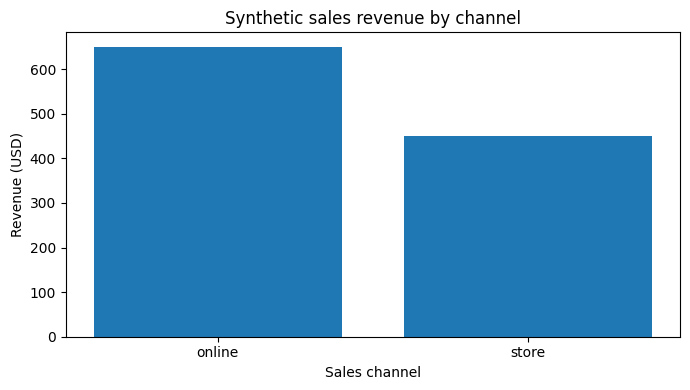

In [14]:
fig, ax = plt.subplots(figsize=(7,4))
ax.bar(channel_summary.sales_channel, channel_summary.sales_amount)
ax.set(xlabel='Sales channel', ylabel='Revenue (USD)', title='Synthetic sales revenue by channel')
fig.tight_layout()
plt.show()

The chart answers the question directly; it does not establish causation. Optional interactive version: `plotly.express.bar(channel_summary, x="sales_channel", y="sales_amount")` with descriptive title and labels.

### Live PostgreSQL equivalent (DBeaver)

```sql
SELECT sales_channel, SUM(sales_amount) AS revenue
FROM sales GROUP BY sales_channel ORDER BY revenue DESC;
```

Use actual results and verify missing channel values, currency and transaction grain. Do not transfer the synthetic conclusions into the final assignment.

### Example 15.4: Reconcile model evaluation totals

**Goal and context.** Keep denominators visible; tiny synthetic samples do not establish model superiority.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
eval_rows=pd.DataFrame({'model':['A','A','B','B'],'correct':[1,0,1,1]})
summary=eval_rows.groupby('model').correct.agg(['sum','count'])
summary['accuracy']=summary['sum']/summary['count']
assert summary['count'].sum()==len(eval_rows)
print(summary)
```

**Expected result:** A 1/2=.5, B 2/2=1.

**Derived practice:** Add one incorrect B response. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

B accuracy 2/3.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

### 5.1 Query walkthrough structure
State the question → explain grain and joins → justify technique → show evidence → interpret implications → state limitation. Avoid reading SQL aloud. Example: a window share retains a channel row while making its contribution relative to the total visible.

```sql
WITH channel_totals AS (
 SELECT sales_channel, SUM(sales_amount)::numeric AS revenue
 FROM sales GROUP BY sales_channel
)
SELECT sales_channel, revenue,
 ROUND(100 * revenue / NULLIF(SUM(revenue) OVER (),0),2) AS share_pct
FROM channel_totals ORDER BY revenue DESC;
```

This is a lecture example, not a complete six-query submission. Explain why a window function preserves channel-level grain. Validate denominators and null values.

### 5.2 Execution-plan practice (Module 12 revisit)

```sql
EXPLAIN (ANALYZE, BUFFERS)
SELECT sales_channel, SUM(sales_amount) AS revenue
FROM sales GROUP BY sales_channel;
```

Run in DBeaver. EXPLAIN ANALYZE executes the statement; use read-only SELECT here. Costs are not milliseconds. Actual times and rows are averages per loop, so consider loops; parent timing includes children. Do not add inclusive node times or call the root the bottleneck solely because it has the largest inclusive time. Identify the highest reported time as requested, then distinguish likely expensive work from inherited time. A sequential scan may be reasonable when nearly all rows are needed.

### Example 15.5: Present an operational metric with uncertainty

**Goal and context.** A credible walkthrough explains grain, denominator, validation and limitations before recommending action.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import pandas as pd
requests=pd.DataFrame({'route':['east','east','west'],'success':[1,0,1]})
report=requests.groupby('route').success.agg(['sum','count','mean'])
print(report)
```

**Expected result:** east 1/2=.5; west 1/1=1.

**Derived practice:** Add a failed west request. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

Both routes .5; avoid overinterpreting sample sizes.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## Part 6 - Common mistakes and AI-code critique
Review this deliberately flawed example without executing it:
```python
# DO NOT RUN
summary.to_sql("sales", engine, if_exists="replace")
with engine.connect() as conn:
    conn.execute(text("INSERT INTO my_stage VALUES (1)"))
```
Identify destructive replacement, accidental index column, missing column list and missing commit. Correct approach: owned temporary staging table, explicit columns and transaction scope. See Part 1 for a safe verified implementation.

Additional critique: a generated answer claims five pooled connections always open at startup, DuckDB cannot persist data, and pre_ping prevents all disconnects. Explain why each claim is too strong using the official references. Review rather than trusting generated code.

### Example 15.6: Rollback a failed publication

**Goal and context.** A transaction rolls back both inserts after the duplicate-key failure.

**Predict → run → inspect.** Before running, predict the output. Run this standalone example in Python with the indicated dependencies. It does not use course credentials.

```python
import sqlite3
from contextlib import closing
with closing(sqlite3.connect(':memory:')) as conn:
    conn.execute('CREATE TABLE published(id INTEGER PRIMARY KEY)')
    try:
        with conn:
            conn.execute('INSERT INTO published VALUES (1)')
            conn.execute('INSERT INTO published VALUES (1)')
    except sqlite3.IntegrityError:
        pass
    print(conn.execute('SELECT count(*) FROM published').fetchone()[0])
```

**Expected result:** 0.

**Derived practice:** Change second ID to 2. Predict the changed result before running.

<details>
<summary>Reveal self-check</summary>

2 rows commit.

</details>

**Transfer:** Explain which assumption would need checking before applying this technique to production data. Record the result and compare it with your prediction.

## Part 7 - Practice
1. Adapt the textbook customer-per-state summary to the fixture; reset the index before writing with index=False.
2. Within a temporary table transaction, verify state counts and distinct keys; deliberately raise an exception before commit on a disposable dataset and inspect rollback behavior.
3. Modify the DuckDB query to calculate channel revenue shares using a CTE and window function.
4. Rehearse one real project query in 90 seconds using question, rationale, evidence and implication.
5. Run a real read-only execution plan and write the four-observation annotation.

In [15]:
state_counts = df_customers.groupby('state', as_index=False).customer_id.count().rename(columns={'customer_id':'customer_count'})
assert state_counts.customer_count.sum() == 4
state_counts

,state,customer_count
0,OR,1
1,TX,1
2,WA,2


Self-check: WA 2, OR 1, TX 1. A unique customer key makes counting rows appropriate in this fixture. In real data inspect null states and duplicate keys.

### Knowledge check
- Does append deduplicate? No; constraints and explicit conflict policies are needed.
- Does a successful engine constructor prove authentication? No; connect and run a query.
- Does returning a connection always close its physical socket? No, pooled connections can be reused.
- Is DuckDB required in the final project? No.
- Can an index be slower for a whole-table aggregate? Yes; inspect the actual plan.
- Does a chart justify causation? No; state the limits of observational evidence.

In [16]:
engine.dispose()

## Module and course summary
From introductory Pagila SELECTs to ZoomZoom joins, CTEs, transformations, windows, semi-structured data, text analytics, performance, recursive and statistical SQL, and Python integration: the transferable skill is choosing a technique, validating evidence and communicating why it matters. Correctness and a clear analytical story take priority over complexity.

## References
- Shan, J., Li, H., Goldwasser, M., Malik, U., & Johnston, B. (2025). *SQL for Data Analytics* (4th ed.). Packt. Chapter 4, pp. 72–79.
- Course Canvas Module 15.
- [pandas DataFrame.to_sql](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_sql.html)
- [SQLAlchemy 2.0 pooling](https://docs.sqlalchemy.org/en/20/core/pooling.html) and [connections](https://docs.sqlalchemy.org/en/20/core/connections.html)
- [psycopg2 cursor API](https://www.psycopg.org/docs/cursor.html) and [basic usage](https://www.psycopg.org/docs/usage.html)
- [DuckDB Python API](https://duckdb.org/docs/current/clients/python/overview) and [DataFrame integration](https://duckdb.org/docs/stable/guides/python/sql_on_pandas)
- [PostgreSQL 16 EXPLAIN](https://www.postgresql.org/docs/16/using-explain.html), [transactions](https://www.postgresql.org/docs/16/tutorial-transactions.html), [INSERT](https://www.postgresql.org/docs/16/sql-insert.html)
- McKinney, W. (2022). *Python for Data Analysis* (3rd ed.), [Chapter 6](https://wesmckinney.com/book/accessing-data).
- [Plotly Express](https://plotly.com/python/plotly-express/)